In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import tomotopy as tp
from tomotopy.utils import Corpus
from tomotopy.coherence import Coherence
import matplotlib.pyplot as plt
import seaborn as sns
import pyLDAvis

In [2]:
df = pd.read_csv("cleaned_corpus.csv", index_col = 0, parse_dates = ['approved_date'])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 994 entries, repacts:datasets/markdown/repacts/2016/ra_10923_2016.md to repacts:datasets/markdown/repacts/2022/ra_11933_2022.md
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   source           994 non-null    object        
 1   year             994 non-null    int64         
 2   month            994 non-null    object        
 3   path             994 non-null    object        
 4   basename         994 non-null    object        
 5   title            994 non-null    object        
 6   day              994 non-null    int64         
 7   year_extracted   994 non-null    int64         
 8   approved_date    994 non-null    datetime64[ns]
 9   cleaned_content  994 non-null    object        
dtypes: datetime64[ns](1), int64(3), object(6)
memory usage: 85.4+ KB


In [3]:
df['quarter'] = df.approved_date.dt.quarter
# q1 = df[df.quarters == 1]
# q2 = df[df.quarters == 2]
# q3 = df[df.quarters == 3]
# q4 = df[df.quarters == 4]

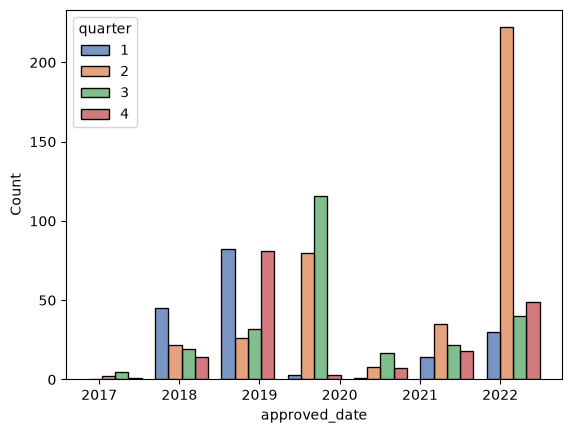

In [4]:
g = sns.histplot(x = 'approved_date', bins = 7, data = df, hue='quarter', multiple="dodge", shrink=.8, palette="deep")

source: https://github.com/bab2min/tomotopy/blob/main/examples/lda_basic.py

In [15]:
def raw_corpus_and_labeling_example(df):
    from nltk.stem.porter import PorterStemmer
    from nltk.corpus import stopwords
    stemmer = PorterStemmer()
    stops = set(stopwords.words('english'))
    corpus = tp.utils.Corpus()
    # data_feeder yields a tuple of (raw string, user data) or a str (raw string)
    
    for text in df['cleaned_content']:
        corpus.add_doc(text.split())
    # corpus.process(open(input_file, encoding='utf-8'))

    # make LDA model and train
    mdl = tp.LDAModel(k=5, min_cf=10, min_df=5, corpus=corpus)
    mdl.train(0)
    print('Num docs:', len(mdl.docs), ', Vocab size:', len(mdl.used_vocabs), ', Num words:', mdl.num_words)
    print('Removed top words:', mdl.removed_top_words)
    mdl.train(1000, workers=1)
    mdl.summary()
    
    # extract candidates for auto topic labeling
    extractor = tp.label.PMIExtractor(min_cf=10, min_df=5, max_len=5, max_cand=10000, normalized=True)
    cands = extractor.extract(mdl)

    labeler = tp.label.FoRelevance(mdl, cands, min_df=5, smoothing=1e-2, mu=0.25)
    for k in range(mdl.k):
        print("== Topic #{} ==".format(k))
        print("Labels:", ', '.join(label for label, score in labeler.get_topic_labels(k, top_n=5)))
        for word, prob in mdl.get_topic_words(k, top_n=10):
            print(word, prob, sep='\t')
        print()

print('Running LDA from raw corpus and Labeling')
period = df[df.year == 2020]
print(f"found {len(period)} records for year {2019} quarter {1}")
if len(period):
    raw_corpus_and_labeling_example(df)

Running LDA from raw corpus and Labeling
found 54 records for year 2019 quarter 1
Num docs: 994 , Vocab size: 3800 , Num words: 692202
Removed top words: []
<Basic Info>
| LDAModel (current version: 0.14.0)
| 994 docs, 692202 words
| Total Vocabs: 14820, Used Vocabs: 3800
| Entropy of words: 7.16063
| Entropy of term-weighted words: 7.16063
| Removed Vocabs: <NA>
|
<Training Info>
| Iterations: 1000, Burn-in steps: 0
| Optimization Interval: 10
| Log-likelihood per word: -6.95701
|
<Initial Parameters>
| tw: TermWeight.ONE
| min_cf: 10 (minimum collection frequency of words)
| min_df: 5 (minimum document frequency of words)
| rm_top: 0 (the number of top words to be removed)
| k: 5 (the number of topics between 1 ~ 32767)
| alpha: 0.1 (hyperparameter of Dirichlet distribution for document-topic, given as a single `float` in case of symmetric prior and as a list with length `k` of `float` in case of asymmetric prior.)
| eta: 0.01 (hyperparameter of Dirichlet distribution for topic-word)

In [12]:
period = df[(df.year == 2019) & (df.quarter == 1)]
print(f"found {len(period)} records for year {2019} quarter {1}")
corpus = Corpus()
if len(period):
    for text in period['cleaned_content']:
        corpus.add_doc(text.split())

mdl = tp.LDAModel(min_df=5, rm_top=40, k=30, corpus=corpus)
mdl.train(0)

print('Num docs:{}, Num Vocabs:{}, Total Words:{}'.format(
    len(mdl.docs), len(mdl.used_vocabs), mdl.num_words
))
print('Removed Top words: ', *mdl.removed_top_words)

# Let's train the model
mdl.train(1000, workers=1)
mdl.summary()

topic_term_dists = np.stack([mdl.get_topic_word_dist(k) for k in range(mdl.k)])
doc_topic_dists = np.stack([doc.get_topic_dist() for doc in mdl.docs])
doc_topic_dists /= doc_topic_dists.sum(axis=1, keepdims=True)
doc_lengths = np.array([len(doc.words) for doc in mdl.docs])
vocab = list(mdl.used_vocabs)
term_frequency = mdl.used_vocab_freq

prepared_data = pyLDAvis.prepare(
    topic_term_dists, 
    doc_topic_dists, 
    doc_lengths, 
    vocab, 
    term_frequency,
    start_index=0, # tomotopy starts topic ids with 0, pyLDAvis with 1
    sort_topics=False # IMPORTANT: otherwise the topic_ids between pyLDAvis and tomotopy are not matching!
)
pyLDAvis.save_html(prepared_data, 'ldavis.html')

found 82 records for year 2019 quarter 1
Num docs:82, Num Vocabs:1505, Total Words:60491
Removed Top words:  provide corporation board philippine commission member house provision president law service include director university regulation health rule government person program within child national general public secretary school purpose right use case necessary stock fund system development grantee education subject tax


c:\Users\crsst\Documents\Dev\csci-261-03\.venv\Lib\site-packages\tomotopy\models.py:637: RuntimeWarning: The training result may differ even with fixed seed if `workers` != 1.
  return self._train(iterations, workers, parallel, freeze_topics, callback_interval, callback)


<Basic Info>
| LDAModel (current version: 0.14.0)
| 82 docs, 60491 words
| Total Vocabs: 5492, Used Vocabs: 1505
| Entropy of words: 6.86632
| Entropy of term-weighted words: 6.86632
| Removed Vocabs: provide corporation board philippine commission member house provision president law service include director university regulation health rule government person program within child national general public secretary school purpose right use case necessary stock fund system development grantee education subject tax
|
<Training Info>
| Iterations: 1000, Burn-in steps: 0
| Optimization Interval: 10
| Log-likelihood per word: -6.84362
|
<Initial Parameters>
| tw: TermWeight.ONE
| min_cf: 0 (minimum collection frequency of words)
| min_df: 5 (minimum document frequency of words)
| rm_top: 40 (the number of top words to be removed)
| k: 30 (the number of topics between 1 ~ 32767)
| alpha: 0.1 (hyperparameter of Dirichlet distribution for document-topic, given as a single `float` in case of sym

In [11]:
years = set(df['year'])
quarters = set(df['quarter'])
models = {}
for y in years:
    for q in quarters:
        # collect into corpus obj
        corpus = Corpus()
        period = df[(df.year == y) & (df.quarter == q)] # pyright: ignore[reportUnknownVariableType]
        print(f"found {len(period)} records for year {y} quarter {q}")
        if len(period):
            for text in period['cleaned_content']: # pyright: ignore[reportUnknownVariableType]
                corpus.add_doc(text.split()) # pyright: ignore[reportUnknownArgumentType, reportUnknownMemberType]

            # training the model
            seed = 357
            model = tp.LDAModel(k = 40, corpus = corpus, seed = seed)
            iters = 1000
            model.train(iterations=iters, workers=1) # pyright: ignore[reportCallIssue, reportUnknownMemberType]
            models[(y, q)] = model

            sample_docs = 5
            print("Samples:")
            idx = 0
            list_period = period.index.tolist()
            for doc in model.docs:
                if idx > sample_docs:
                    break
                top_topics = doc.get_topics(top_n = 1)
                topic, score = top_topics[0]
                print(f"{df.loc[list_period[idx], 'basename']}: #{topic} ({score:0.2f}%)")
                idx += 1
        else:
            print("skipping, no records")

len(models)

found 0 records for year 2016 quarter 1
skipping, no records
found 0 records for year 2016 quarter 2
skipping, no records
found 0 records for year 2016 quarter 3
skipping, no records
found 1 records for year 2016 quarter 4
Samples:
ra_10923_2016: #20 (0.08%)
found 0 records for year 2017 quarter 1
skipping, no records
found 2 records for year 2017 quarter 2
Samples:
ra_10925_2017: #27 (0.08%)
ra_10926_2017: #27 (0.08%)
found 24 records for year 2017 quarter 3
Samples:
ra_10927_2017: #16 (0.39%)
ra_10928_2017: #3 (0.29%)
ra_10930_2017: #24 (0.30%)
ra_10931_2017: #28 (0.17%)
ra_10932_2017: #32 (0.25%)
ra_10933_2017: #9 (0.33%)
found 14 records for year 2017 quarter 4
Samples:
ra_10952_2017: #16 (0.38%)
ra_10953_2017: #26 (0.42%)
ra_10954_2017: #29 (0.42%)
ra_10955_2017: #13 (0.42%)
ra_10956_2017: #26 (0.45%)
ra_10957_2017: #26 (0.40%)
found 45 records for year 2018 quarter 1
Samples:
ra_10967_2018: #26 (0.36%)
ra_10968_2018: #29 (0.34%)
ra_10969_2018: #24 (0.37%)
ra_10970_2018: #11 (0.26

23

In [12]:
def top_words(model, k):
    """Print the top words for topic k in a model."""
    top_words = model.get_topic_words(topic_id = k, top_n = 10)
    top_words = [f"{word} ({score:0.4f}%)" for (word, score) in top_words]
    print(f"Topic {k}: {', '.join(top_words)}")

for k,model in models.items(): # pyright: ignore[reportUnknownVariableType]
    year, quarter = k # pyright: ignore[reportUnknownVariableType]
    print(f"topics for year {year} quarter {quarter}")
    for i in range(model.k): # pyright: ignore[reportUnknownArgumentType, reportUnknownMemberType]
        top_words(model, i) # pyright: ignore[reportUnknownArgumentType]

# TODO: consult excluding numbers, days of the week/month (incl. 'day'), other senate terms (article, senate, representative [excluding house kasi it can mean 2 things])
#ALS naging al https://lawphil.net/statutes/repacts/ra2020/ra_11510_2020.html

topics for year 2016 quarter 4
Topic 0: hold (0.3942%), effectivity (0.1581%), commmence (0.0795%), necessary (0.0795%), lutgardo (0.0795%), pareja (0.0795%), hundred (0.0008%), thousand (0.0008%), follow (0.0008%), provision (0.0008%)
Topic 1: remain (0.1716%), regular (0.0863%), successor (0.0863%), project (0.0863%), bridge (0.0863%), creation (0.0863%), give (0.0863%), commission (0.0863%), inconsisten (0.0863%), provision (0.0009%)
Topic 2: appointment (0.3520%), maintenance (0.1769%), sixty (0.1769%), kabataan (0.0018%), barangay (0.0018%), hundred (0.0018%), hold (0.0018%), thousand (0.0018%), follow (0.0018%), provision (0.0018%)
Topic 3: election (0.0058%), sangguniang (0.0058%), kabataan (0.0058%), barangay (0.0058%), hundred (0.0058%), hold (0.0058%), thousand (0.0058%), follow (0.0058%), provision (0.0058%), appropriation (0.0058%)
Topic 4: provision (0.3904%), twenty (0.1310%), hiring (0.1310%), reform (0.1310%), kabataan (0.0013%), barangay (0.0013%), hundred (0.0013%), h

comparing the topic words versus the top topic for some sample docs, I think I need to spread the topics more because for https://lawphil.net/statutes/repacts/ra2017/ra_10927_2017.html the focus was "An Act Designating Casinos as Covered Persons Under Republic Act No. 9160, Otherwise Known as the "Anti-Money Laundering Act of 2001", as Amended" but the top words were "Topic 0: case (0.0260%), provision (0.0180%), provide (0.0172%), follow (0.0144%), law (0.0144%)", or use them as stopwords (check TF-IDF first pano magwowork)

In [13]:
for k,model in models.items():
    year, quarter = k # pyright: ignore[reportUnknownVariableType]
    print(f"words for year {year} quarter {quarter}")
    doc = model.docs[0] # sample first document
    word_to_topic = list(zip(doc, doc.topics))
    for word in range(5):
        word, topic = word_to_topic[word]
        print(f"Word: {word}")
        top_words(model, topic)

words for year 2016 quarter 4
Word: seventeenth
Topic 33: regulation (0.2368%), philippine (0.1581%), seventeenth (0.0795%), repeal (0.0795%), session (0.0795%), subsequently (0.0795%), exclusively (0.0795%), speaker (0.0795%), barangay (0.0008%), hundred (0.0008%)
Word: first
Topic 15: barangay (0.5417%), conduct (0.0725%), amount (0.0725%), date (0.0725%), office (0.0364%), first (0.0364%), incumbent (0.0364%), development (0.0364%), cesar (0.0364%), hundred (0.0004%)
Word: regular
Topic 1: remain (0.1716%), regular (0.0863%), successor (0.0863%), project (0.0863%), bridge (0.0863%), creation (0.0863%), give (0.0863%), commission (0.0863%), inconsisten (0.0863%), provision (0.0009%)
Word: session
Topic 33: regulation (0.2368%), philippine (0.1581%), seventeenth (0.0795%), repeal (0.0795%), session (0.0795%), subsequently (0.0795%), exclusively (0.0795%), speaker (0.0795%), barangay (0.0008%), hundred (0.0008%)
Word: begin
Topic 17: kabataan (0.4122%), read (0.1127%), hundred (0.0753%

In [18]:
for k,model in models.items():
    topic_sizes = model.get_count_by_topics()
    print("Number of words per topic:")
    for i in range(model.k):
        print(f"+ Topic #{i}: {topic_sizes[i]} words")


Number of words per topic:
+ Topic #0: 46 words
+ Topic #1: 28 words
+ Topic #2: 20 words
+ Topic #3: 72 words
+ Topic #4: 22 words
+ Topic #5: 29 words
+ Topic #6: 31 words
+ Topic #7: 23 words
+ Topic #8: 34 words
+ Topic #9: 41 words
Number of words per topic:
+ Topic #0: 117 words
+ Topic #1: 199 words
+ Topic #2: 199 words
+ Topic #3: 149 words
+ Topic #4: 220 words
+ Topic #5: 174 words
+ Topic #6: 172 words
+ Topic #7: 91 words
+ Topic #8: 149 words
+ Topic #9: 181 words
Number of words per topic:
+ Topic #0: 1306 words
+ Topic #1: 517 words
+ Topic #2: 923 words
+ Topic #3: 1278 words
+ Topic #4: 2647 words
+ Topic #5: 1307 words
+ Topic #6: 1787 words
+ Topic #7: 1212 words
+ Topic #8: 1816 words
+ Topic #9: 770 words
Number of words per topic:
+ Topic #0: 2372 words
+ Topic #1: 1447 words
+ Topic #2: 2563 words
+ Topic #3: 2541 words
+ Topic #4: 861 words
+ Topic #5: 1221 words
+ Topic #6: 1455 words
+ Topic #7: 1116 words
+ Topic #8: 1376 words
+ Topic #9: 1564 words
Number 

todo: coherence score https://www.geeksforgeeks.org/nlp/topic-modeling-using-latent-dirichlet-allocation-lda/